# Name : Luqman khan
# SID : S2024266054

Task No 5

In [5]:
# SECTION 0 : IMPORTS AND SETTINGS

import json
import os
import random
import shutil
import time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

try:                                    # `display` exists in Colab / Jupyter
    from IPython.display import display
except ImportError:                     # plain Python: just print instead
    display = print

# ---- Settings you may want to change ----------------------------------------
SEED = 42
IMAGE_SIZE = (100, 100)
BATCH_SIZE = 50
VGG_EPOCHS = 10                  # VGG16 (full data and 10% data)
SCRATCH_FULL_EPOCHS = 25         # scratch CNN on full data (same as Task 4)
SCRATCH_LOW_EPOCHS = 10          # scratch CNN on 10% data
LOW_DATA_FRACTION = 0.10         # "10% of the training data"
SAVE_EVERY_N_EPOCHS = 1          # write a checkpoint to Drive every N epochs
                                 # (a VGG16 checkpoint is ~100 MB: use 2-3 to save less often)

USE_KAGGLEHUB = True             # download the dataset from Kaggle
DATASET_ROOT = None              # OR set a folder that contains Training/ and Test/

# Task 4's RGB classifier is re-used here, so these must match Task 4.
TASK4_EPOCHS = 25

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

OUTPUT_DIR = Path("/content/Task5_Results")
PLOTS_DIR = OUTPUT_DIR / "plots"
CSV_DIR = OUTPUT_DIR / "csv"
MODELS_DIR = OUTPUT_DIR / "models"
for folder in (PLOTS_DIR, CSV_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


def save_and_show(path, dpi=180):
    """Small helper: tidy the layout, save the current figure, then show it."""
    plt.tight_layout()
    plt.savefig(path, dpi=dpi)
    plt.show()



TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
# SECTION 1 : GOOGLE DRIVE + CHECKPOINTS
# ------------------------------------------------------------------------------
# Colab can disconnect at any time and then everything in /content is lost.
# So while a model trains we keep copying it to Google Drive. After a
# disconnect, run the notebook again: the model is reloaded from Drive and
# training continues from the last finished epoch.
# ==============================================================================
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CHECKPOINT_DIR = Path("/content/drive/MyDrive/Task5_Checkpoints")
    TASK4_CHECKPOINT_DIR = Path("/content/drive/MyDrive/Task4_Checkpoints")
except ImportError:
    print("Not running in Colab - checkpoints will be stored locally instead.")
    CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
    TASK4_CHECKPOINT_DIR = Path("/content/Task4_Results/checkpoints")

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
print("Task 5 checkpoints are stored in:", CHECKPOINT_DIR)


class DriveCheckpoint(keras.callbacks.Callback):
    """Keras callback: after each epoch, record the results and (every N
    epochs) save the full model + training progress to Drive."""

    def __init__(self, ckpt_dir, state, save_every=1):
        super().__init__()
        self.ckpt_dir = Path(ckpt_dir)
        self.state = state                       # progress dictionary (see below)
        self.save_every = save_every
        self._last_saved_epoch = state["epochs_completed"]

    def on_epoch_begin(self, epoch, logs=None):
        self._epoch_start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.state["epoch_times"].append(time.time() - self._epoch_start)
        for name, value in (logs or {}).items():
            self.state["history"].setdefault(name, []).append(float(value))
        self.state["epochs_completed"] = epoch + 1

        if (epoch + 1) % self.save_every == 0:
            self._save()

    def on_train_end(self, logs=None):
        if self.state["epochs_completed"] != self._last_saved_epoch:
            self._save()

    def _save(self):
        # Save to a temporary name first, then rename. If Colab disconnects
        # in the middle of saving, the previous good checkpoint stays intact.
        tmp_model = self.ckpt_dir / "tmp_latest.keras"
        self.model.save(str(tmp_model))
        os.replace(tmp_model, self.ckpt_dir / "latest.keras")

        tmp_state = self.ckpt_dir / "state.json.tmp"
        tmp_state.write_text(json.dumps(self.state))
        os.replace(tmp_state, self.ckpt_dir / "state.json")

        self._last_saved_epoch = self.state["epochs_completed"]
        print(f"  -> checkpoint saved to Drive (epoch {self._last_saved_epoch})")


def train_with_checkpoints(name, model, train_data, val_data, epochs):
    """Train `model` and keep a checkpoint on Drive.

    * No checkpoint on Drive -> train from epoch 0.
    * Checkpoint exists      -> reload the model and continue where it stopped.
    * Already finished       -> reload the model and skip training.

    Returns (model, history, timer). `history.history` and `timer.epoch_times`
    include the epochs finished BEFORE a restart too.
    To retrain from scratch, delete the folder  CHECKPOINT_DIR/<name>.
    """
    ckpt_dir = CHECKPOINT_DIR / name
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    model_path = ckpt_dir / "latest.keras"
    state_path = ckpt_dir / "state.json"

    # "state" remembers how far training got.
    state = {"epochs_completed": 0, "history": {}, "epoch_times": []}

    if model_path.exists() and state_path.exists():
        state = json.loads(state_path.read_text())
        model = keras.models.load_model(str(model_path))
        print(f"[{name}] Loaded checkpoint from Drive: "
              f"{state['epochs_completed']}/{epochs} epochs already done.")
    else:
        print(f"[{name}] No checkpoint found - training from scratch.")

    start_epoch = state["epochs_completed"]
    if start_epoch < epochs:
        model.fit(
            train_data,
            validation_data=val_data,
            epochs=epochs,
            initial_epoch=start_epoch,
            callbacks=[DriveCheckpoint(ckpt_dir, state, SAVE_EVERY_N_EPOCHS)],
            verbose=1,
        )
    else:
        print(f"[{name}] Already trained for {start_epoch} epochs - skipping training.")

    history = SimpleNamespace(history=state["history"])
    timer = SimpleNamespace(epoch_times=state["epoch_times"])
    return model, history, timer



Mounted at /content/drive
Task 5 checkpoints are stored in: /content/drive/MyDrive/Task5_Checkpoints


In [7]:
# SECTION 2 : DOWNLOAD AND LOCATE THE DATASET
# ------------------------------------------------------------------------------
# Fruits-360 has two folders we need:  Training/  and  Test/
# Each of them contains one sub-folder per fruit class.
# ==============================================================================
def is_dataset_root(path):
    """True if `path` contains both a Training/ and a Test/ folder."""
    path = Path(path)
    return (path / "Training").is_dir() and (path / "Test").is_dir()


def find_dataset_root(base, max_depth=6):
    """Search inside `base` for the folder holding Training/ and Test/.
    Kaggle's download may contain several versions of the dataset; this task
    uses 100x100 images, so a path containing '100x100' is preferred."""
    found = []
    for current, dirs, _ in os.walk(base):
        current = Path(current)
        if is_dataset_root(current):
            found.append(current)
            dirs[:] = []                              # no need to look deeper
        elif len(current.relative_to(base).parts) >= max_depth:
            dirs[:] = []
    if not found:
        return None
    preferred = [p for p in found if "100x100" in str(p)]
    return sorted(preferred or found)[0]


def locate_dataset():
    """Return the dataset folder (the one containing Training/ and Test/)."""
    if DATASET_ROOT:                                  # option 1: you gave a folder
        root = Path(DATASET_ROOT)
        if not is_dataset_root(root):
            raise FileNotFoundError(
                f"{root} must contain both Training/ and Test/ folders.")
        return root

    if USE_KAGGLEHUB:                                 # option 2: download from Kaggle
        try:
            import kagglehub
        except ImportError:
            import subprocess
            import sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub

        download_path = kagglehub.dataset_download("moltean/fruits")
        print("Kaggle download path:", download_path)
        root = find_dataset_root(download_path)
        if root is None:
            raise FileNotFoundError(
                "Training/ and Test/ were not found inside the Kaggle download.")
        return root

    raise FileNotFoundError("Set DATASET_ROOT, or set USE_KAGGLEHUB = True.")


dataset_root = locate_dataset()
TRAIN_DIR = dataset_root / "Training"
TEST_DIR = dataset_root / "Test"
print("Dataset root   :", dataset_root)
print("Training folder:", TRAIN_DIR)
print("Test folder    :", TEST_DIR)



100%|██████████| 8.52G/8.52G [07:16<00:00, 20.9MB/s]

Extracting files...


Kaggle download path: /root/.cache/kagglehub/datasets/moltean/fruits/versions/113
Dataset root   : /root/.cache/kagglehub/datasets/moltean/fruits/versions/113/fruits-360_100x100/fruits-360
Training folder: /root/.cache/kagglehub/datasets/moltean/fruits/versions/113/fruits-360_100x100/fruits-360/Training
Test folder    : /root/.cache/kagglehub/datasets/moltean/fruits/versions/113/fruits-360_100x100/fruits-360/Test


In [8]:
# SECTION 3 : CHECK THE CLASSES AND COUNT THE IMAGES

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}


def list_class_names(folder):
    """Names of all class sub-folders (ignoring hidden/system folders and
    folders without images)."""
    names = []
    for sub in Path(folder).iterdir():
        if not sub.is_dir() or sub.name.startswith(".") or sub.name == "__MACOSX":
            continue
        if any(p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS for p in sub.iterdir()):
            names.append(sub.name)
    return sorted(names)


def count_images(folder, classes=None):
    """Total number of image files in the class folders of `folder`
    (only the folders listed in `classes`, if given)."""
    folder = Path(folder)
    subfolders = [folder / c for c in classes] if classes else [p for p in folder.iterdir() if p.is_dir()]
    return sum(1 for sub in subfolders
               for p in sub.rglob("*")
               if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)


train_classes = list_class_names(TRAIN_DIR)
test_classes = list_class_names(TEST_DIR)

only_in_train = sorted(set(train_classes) - set(test_classes))
only_in_test = sorted(set(test_classes) - set(train_classes))

print("Classes in Training:", len(train_classes))
print("Classes in Test    :", len(test_classes))
if only_in_train:
    print(f"\nOnly in Training ({len(only_in_train)}), ignored:", only_in_train)
if only_in_test:
    print(f"\nOnly in Test ({len(only_in_test)}), ignored:", only_in_test)

# Keep only the classes that exist in BOTH folders, so the Training and Test
# sets always use the same label numbers.
class_names = sorted(set(train_classes) & set(test_classes))
if not class_names:
    raise ValueError(
        f"Training and Test have no class folders in common.\n"
        f"TRAIN_DIR = {TRAIN_DIR}\nTEST_DIR  = {TEST_DIR}\n"
        "Check that both paths point to the same dataset version.")

# The number of classes comes from the dataset that was actually loaded.
NUM_CLASSES = len(class_names)

print("\nNumber of classes used:", NUM_CLASSES)
print("Total Training images :", count_images(TRAIN_DIR, class_names))
print("Total Test images     :", count_images(TEST_DIR, class_names))

Classes in Training: 278
Classes in Test    : 278

Only in Training (1), ignored: ['BlackBerry 4']

Only in Test (1), ignored: ['Blackberry 4']

Number of classes used: 277
Total Training images : 149026
Total Test images     : 49640


In [9]:
# SECTION 4 : IMAGE GENERATORS
# ------------------------------------------------------------------------------
# A "generator" reads images from the folders in batches while training.
# We need two kinds because the two networks expect different pixel scaling:
#   * VGG16 expects its own preprocessing (preprocess_input) and we also use
#     simple augmentation (flip / small shifts) on its training images.
#   * The scratch CNN from Task 4 expects pixels simply divided by 255.
# Each kind gives three generators: train (80%), validation (20%), test.
# ==============================================================================
VGG_PREPROCESSING = {"preprocessing_function": preprocess_input}
SCRATCH_PREPROCESSING = {"rescale": 1.0 / 255.0}
AUGMENTATION = {"horizontal_flip": True, "width_shift_range": 0.1, "height_shift_range": 0.1}


def flow_from_folder(datagen, directory, **options):
    """Read images + integer labels from a folder, using our common settings."""
    return datagen.flow_from_directory(
        directory,
        classes=class_names,              # fixes the class order for every generator
        target_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="sparse",
        **options,
    )


def make_generators(preprocessing, augment):
    """Return (train, validation, test) generators."""
    train_datagen = ImageDataGenerator(
        **preprocessing, **(AUGMENTATION if augment else {}), validation_split=0.2)
    validation_datagen = ImageDataGenerator(**preprocessing, validation_split=0.2)
    test_datagen = ImageDataGenerator(**preprocessing)

    train = flow_from_folder(train_datagen, TRAIN_DIR, subset="training", shuffle=True, seed=SEED)
    validation = flow_from_folder(validation_datagen, TRAIN_DIR, subset="validation", shuffle=False)
    test = flow_from_folder(test_datagen, TEST_DIR, shuffle=False)
    return train, validation, test


train_generator, validation_generator, test_generator = make_generators(
    VGG_PREPROCESSING, augment=True)
scratch_train_generator, scratch_validation_generator, scratch_test_generator = make_generators(
    SCRATCH_PREPROCESSING, augment=False)

print("Training images  :", train_generator.samples)
print("Validation images:", validation_generator.samples)
print("Testing images   :", test_generator.samples)
print("Class count      :", len(train_generator.class_indices))



Found 119315 images belonging to 277 classes.
Found 29711 images belonging to 277 classes.
Found 49640 images belonging to 277 classes.
Found 119315 images belonging to 277 classes.
Found 29711 images belonging to 277 classes.
Found 49640 images belonging to 277 classes.
Training images  : 119315
Validation images: 29711
Testing images   : 49640
Class count      : 277


In [10]:
# SECTION 5 : 5(a) BUILD THE VGG16 TRANSFER-LEARNING MODEL
# ==============================================================================
def build_vgg16_transfer_model():
    """VGG16 (ImageNet weights, frozen) -> Flatten -> Dense 1000 -> Softmax."""
    base_model = VGG16(weights="imagenet", include_top=False, input_shape=(100, 100, 3))
    base_model.trainable = False                 # frozen: its weights are NOT updated

    inputs = keras.Input(shape=(100, 100, 3))
    features = base_model(inputs, training=False)
    flattened = keras.layers.Flatten(name="transfer_flatten")(features)
    dense_features = keras.layers.Dense(1000, activation="relu", name="transfer_dense_1000")(flattened)
    outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="transfer_predictions")(dense_features)

    model = keras.Model(inputs, outputs, name="VGG16_Fruits360_Transfer_Learning")
    compile_model(model)
    return model


def compile_model(model):
    """Same optimizer, loss and metrics for every model in this task."""
    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy",
                 keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_accuracy")],
    )


def count_parameters(model):
    """Returns (trainable, non-trainable, total) parameter counts."""
    trainable = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    non_trainable = int(sum(np.prod(v.shape) for v in model.non_trainable_weights))
    return trainable, non_trainable, int(model.count_params())


vgg16_model = build_vgg16_transfer_model()
vgg16_model.summary()

# Verify which parameters are trainable (only the new head) and which are frozen (VGG16)
trainable_parameters, non_trainable_parameters, total_parameters = count_parameters(vgg16_model)
vgg_base_parameters = next(
    layer for layer in vgg16_model.layers if isinstance(layer, keras.Model)).count_params()

parameter_summary = pd.DataFrame({
    "Parameter Type": ["Trainable", "Non-trainable", "Total"],
    "Number of Parameters": [trainable_parameters, non_trainable_parameters, total_parameters],
})
display(parameter_summary)
print("VGG16 base parameters         :", vgg_base_parameters)
print("Classification head parameters:", total_parameters - vgg_base_parameters)



58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "VGG16_Fruits360_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_flatten (Flatten)      │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_dense_1000 (Dense)     │ (None, 1000)           │     4,609,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_predictions (Dense)    │ (None, 277)            │       277,277 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,600,965 (74.77 MB)

 Trainable params: 4,886,277 (18.64 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

,Parameter Type,Number of Parameters
0,Trainable,4886277
1,Non-trainable,14714688
2,Total,19600965


VGG16 base parameters         : 14714688
Classification head parameters: 4886277


[vgg16_full_277cls] No checkpoint found - training from scratch.
Epoch 1/10
2387/2387 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.7388 - loss: 2.2671 - top5_accuracy: 0.8872  -> checkpoint saved to Drive (epoch 1)
2387/2387 ━━━━━━━━━━━━━━━━━━━━ 570s 233ms/step - accuracy: 0.8581 - loss: 0.8292 - top5_accuracy: 0.9665 - val_accuracy: 0.8537 - val_loss: 1.1504 - val_top5_accuracy: 0.9820
Epoch 2/10
2387/2387 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.9344 - loss: 0.3640 - top5_accuracy: 0.9970  -> checkpoint saved to Drive (epoch 2)
2387/2387 ━━━━━━━━━━━━━━━━━━━━ 487s 204ms/step - accuracy: 0.9420 - loss: 0.3386 - top5_accuracy: 0.9978 - val_accuracy: 0.8926 - val_loss: 1.4224 - val_top5_accuracy: 0.9898
Epoch 3/10
2387/2387 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step - accuracy: 0.9547 - loss: 0.3142 - top5_accuracy: 0.9986  -> checkpoint saved to Drive (epoch 3)
2387/2387 ━━━━━━━━━━━━━━━━━━━━ 483s 202ms/step - accuracy: 0.9586 - loss: 0.3075 - top5_accuracy: 0.9989 - val_accuracy: 0.

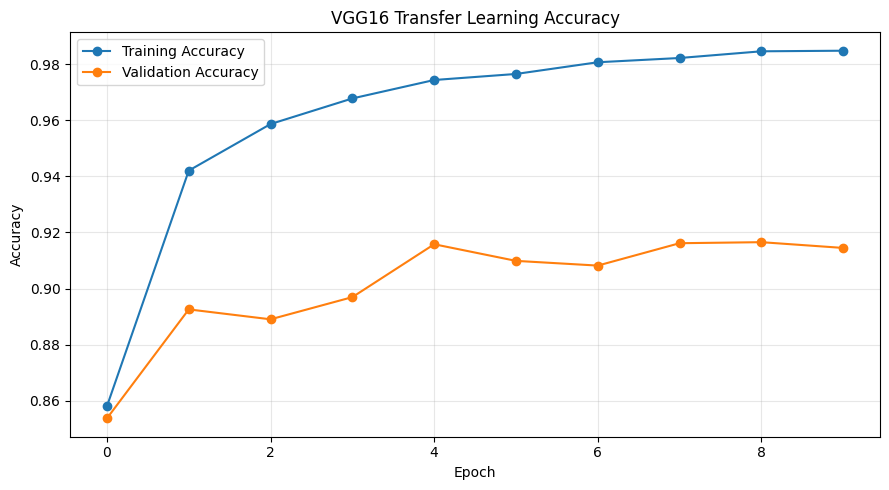

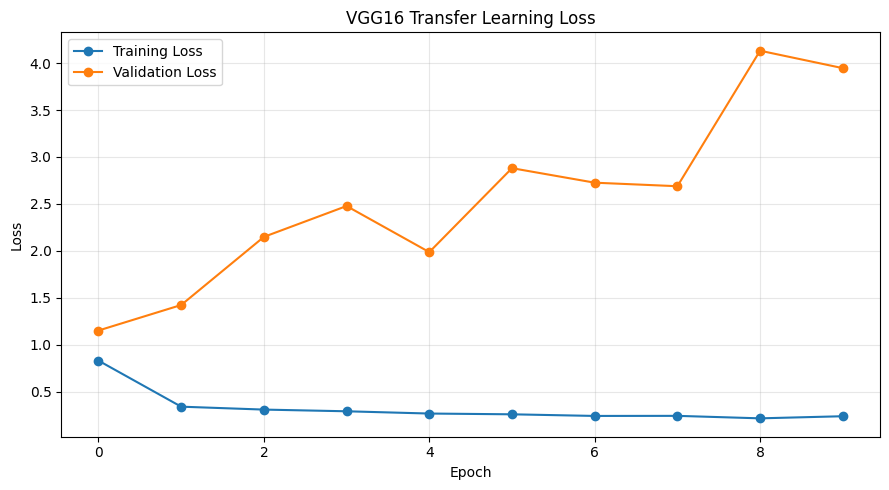

In [11]:
# SECTION 6 : 5(b) TRAIN VGG16 FOR 10 EPOCHS
# ==============================================================================
def evaluate_model(model, generator):
    """Returns (test accuracy, top-5 test accuracy) on the given generator."""
    metrics = model.evaluate(generator, verbose=1, return_dict=True)
    return float(metrics["accuracy"]), float(metrics["top5_accuracy"])


def train_and_evaluate(name, model, train_data, val_data, test_data, epochs):
    """Train (with Drive checkpoints), then measure accuracy on the test set.
    The checkpoint name includes NUM_CLASSES so a checkpoint made with a
    different dataset is never loaded by mistake."""
    model, history, timer = train_with_checkpoints(
        f"{name}_{NUM_CLASSES}cls", model, train_data, val_data, epochs)
    accuracy, top5 = evaluate_model(model, test_data)
    mean_epoch_time = float(np.mean(timer.epoch_times))

    print(f"\n{name} RESULTS")
    print("Test Accuracy      :", accuracy)
    print("Top-5 Test Accuracy:", top5)
    print("Avg Time Per Epoch :", mean_epoch_time)
    print("Total Parameters   :", model.count_params())
    return SimpleNamespace(model=model, history=history, accuracy=accuracy,
                           top5=top5, mean_epoch_time=mean_epoch_time)


def plot_history_metric(history, metric, label, title, save_path):
    """Training vs validation curve of one metric."""
    plt.figure(figsize=(9, 5))
    plt.plot(history.history[metric], marker="o", label=f"Training {label}")
    plt.plot(history.history[f"val_{metric}"], marker="o", label=f"Validation {label}")
    plt.xlabel("Epoch")
    plt.ylabel(label)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    save_and_show(save_path)


# 5(b) trains the model; 5(c) evaluates it on the test set - both happen here.
vgg_full = train_and_evaluate(
    "vgg16_full", vgg16_model,
    train_generator, validation_generator, test_generator, VGG_EPOCHS)

plot_history_metric(vgg_full.history, "accuracy", "Accuracy",
                    "VGG16 Transfer Learning Accuracy", PLOTS_DIR / "task5_vgg16_accuracy.png")
plot_history_metric(vgg_full.history, "loss", "Loss",
                    "VGG16 Transfer Learning Loss", PLOTS_DIR / "task5_vgg16_loss.png")



In [ ]:
# SECTION 7 : 5(c) THE SCRATCH CNN FROM TASK 4 (FULL DATA)
# ------------------------------------------------------------------------------
# For a fair comparison we need the small CNN trained on the full data.
# Task 4 already trained it, so we first try to load it from Drive.
# Only if it is not available do we train it here.
# ==============================================================================
def build_scratch_cnn(num_classes):
    """The Task 4 CNN: 4 x (Conv 5x5 + MaxPool) -> Dense 1024 -> Dense 256 -> Softmax."""
    L = keras.layers
    model = keras.Sequential([
        L.Input(shape=(100, 100, 3)),
        L.Conv2D(16, (5, 5), activation="relu", padding="same"),
        L.MaxPooling2D((2, 2), strides=2),
        L.Conv2D(32, (5, 5), activation="relu", padding="same"),
        L.MaxPooling2D((2, 2), strides=2),
        L.Conv2D(64, (5, 5), activation="relu", padding="same"),
        L.MaxPooling2D((2, 2), strides=2),
        L.Conv2D(128, (5, 5), activation="relu", padding="same"),
        L.MaxPooling2D((2, 2), strides=2),
        L.Flatten(),
        L.Dense(1024, activation="relu"),
        L.Dense(256, activation="relu"),
        L.Dense(num_classes, activation="softmax"),
    ])
    compile_model(model)
    return model


def load_task4_rgb_model():
    """Try to load the finished Task 4 RGB classifier.
    Returns (model, mean epoch time) or (None, None) if it is not available."""
    # 1) Task 4's Drive checkpoint (needs all epochs finished)
    ckpt_dir = TASK4_CHECKPOINT_DIR / f"rgb_classifier_{NUM_CLASSES}cls"
    model_path, state_path = ckpt_dir / "latest.keras", ckpt_dir / "state.json"
    if model_path.exists() and state_path.exists():
        state = json.loads(state_path.read_text())
        if state["epochs_completed"] >= TASK4_EPOCHS:
            print("Loaded the finished Task 4 RGB model from Drive.")
            return keras.models.load_model(str(model_path)), float(np.mean(state["epoch_times"]))
        print(f"Task 4 checkpoint is unfinished ({state['epochs_completed']}/{TASK4_EPOCHS} epochs).")

    # 2) The model file Task 4 saved at the end of its run (lost if the runtime was reset)
    saved_model_path = Path("/content/Task4_Results/models/fruit_rgb_classifier.keras")
    if saved_model_path.is_file():
        print("Loaded the saved Task 4 RGB model (epoch time unknown).")
        return keras.models.load_model(str(saved_model_path)), float("nan")

    return None, None


scratch_model, scratch_epoch_time = load_task4_rgb_model()

if scratch_model is not None:
    if scratch_model.output_shape[-1] != NUM_CLASSES:
        raise ValueError(f"The Task 4 model has {scratch_model.output_shape[-1]} outputs "
                         f"but this dataset has {NUM_CLASSES} classes.")
    compile_model(scratch_model)               # makes sure accuracy + top-5 are reported
    scratch_accuracy, scratch_top5 = evaluate_model(scratch_model, scratch_test_generator)
    scratch_full = SimpleNamespace(model=scratch_model, history=None, accuracy=scratch_accuracy,
                                   top5=scratch_top5, mean_epoch_time=scratch_epoch_time)
else:
    print("Task 4 model not found - training the scratch CNN here.")
    scratch_full = train_and_evaluate(
        "scratch_full", build_scratch_cnn(NUM_CLASSES),
        scratch_train_generator, scratch_validation_generator, scratch_test_generator,
        SCRATCH_FULL_EPOCHS)

print("Scratch CNN (full data) Test Accuracy:", scratch_full.accuracy)
print("Scratch CNN (full data) Top-5 Accuracy:", scratch_full.top5)
print("Scratch CNN (full data) Parameters   :", scratch_full.model.count_params())
print("Scratch CNN (full data) Avg Epoch (s):", scratch_full.mean_epoch_time)



In [ ]:
# SECTION 8 : 5(c) REPEAT WITH ONLY 10% OF THE TRAINING DATA
# ==============================================================================
LOW_DATA_DIR = Path("/content/task5_low_data_10_percent")


def create_low_data_folder(source_generator, destination, fraction):
    """Pick `fraction` of the training images of EVERY class at random
    (stratified, so each class keeps its share) and link them into `destination`.
    The same SEED always picks the same images, so a resumed run is consistent."""
    if destination.exists():
        shutil.rmtree(destination)
    destination.mkdir(parents=True)

    rng = np.random.default_rng(SEED)
    filepaths = np.asarray(source_generator.filepaths)
    class_ids = np.asarray(source_generator.classes)
    selected_count = 0

    for class_name, class_id in source_generator.class_indices.items():
        indices = np.where(class_ids == class_id)[0]
        how_many = max(1, int(np.ceil(len(indices) * fraction)))
        chosen = rng.choice(indices, size=how_many, replace=False)

        class_folder = destination / class_name
        class_folder.mkdir()
        for index in chosen:
            source = Path(filepaths[index])
            target = class_folder / source.name
            try:
                os.symlink(source, target)       # a link takes no extra disk space
            except OSError:
                shutil.copy2(source, target)     # copy if links are not allowed
            selected_count += 1
    return selected_count


selected_file_count = create_low_data_folder(scratch_train_generator, LOW_DATA_DIR, LOW_DATA_FRACTION)
print("Full training split images :", scratch_train_generator.samples)
print("Selected 10% training images:", selected_file_count)
print("Low-data folder             :", LOW_DATA_DIR)

# Training generators that read only the 10% folder
low_vgg_train_generator = flow_from_folder(
    ImageDataGenerator(**VGG_PREPROCESSING, **AUGMENTATION),
    LOW_DATA_DIR, shuffle=True, seed=SEED)
low_scratch_train_generator = flow_from_folder(
    ImageDataGenerator(**SCRATCH_PREPROCESSING),
    LOW_DATA_DIR, shuffle=True, seed=SEED)

# ---- VGG16 with 10% of the data ---------------------------------------------
vgg_low = train_and_evaluate(
    "vgg16_10pct", build_vgg16_transfer_model(),
    low_vgg_train_generator, validation_generator, test_generator, VGG_EPOCHS)

# ---- Scratch CNN with the same 10% of the data ------------------------------
scratch_low = train_and_evaluate(
    "scratch_10pct", build_scratch_cnn(NUM_CLASSES),
    low_scratch_train_generator, scratch_validation_generator, scratch_test_generator,
    SCRATCH_LOW_EPOCHS)

# ---- Compare the training / validation curves -------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(vgg_full.history.history["accuracy"], label="VGG16 Full Training")
axes[0].plot(vgg_full.history.history["val_accuracy"], label="VGG16 Full Validation")
axes[0].plot(vgg_low.history.history["accuracy"], label="VGG16 10% Training")
axes[0].plot(vgg_low.history.history["val_accuracy"], label="VGG16 10% Validation")
axes[0].set_title("VGG16 Accuracy: Full Data vs 10% Data")

axes[1].plot(scratch_low.history.history["accuracy"], label="Scratch 10% Training")
axes[1].plot(scratch_low.history.history["val_accuracy"], label="Scratch 10% Validation")
axes[1].set_title("Scratch CNN Accuracy with 10% Data")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
save_and_show(PLOTS_DIR / "task5_full_vs_low_data_accuracy.png")



In [ ]:
# SECTION 9 : FINAL COMPARISON TABLE, CHART AND SAVING
# ==============================================================================
def comparison_row(model_name, data_name, n_images, result):
    """One row of the final table."""
    trainable, non_trainable, total = count_parameters(result.model)
    return {
        "Model": model_name,
        "Training Data": data_name,
        "Training Images": n_images,
        "Test Accuracy": result.accuracy,
        "Top-5 Test Accuracy": result.top5,
        "Total Parameters": total,
        "Trainable Parameters": trainable,
        "Non-trainable Parameters": non_trainable,
        "Average Time Per Epoch (seconds)": result.mean_epoch_time,
    }


comparison_table = pd.DataFrame([
    comparison_row("Scratch CNN", "Full", scratch_train_generator.samples, scratch_full),
    comparison_row("VGG16 Transfer Learning", "Full", train_generator.samples, vgg_full),
    comparison_row("Scratch CNN", "10%", low_scratch_train_generator.samples, scratch_low),
    comparison_row("VGG16 Transfer Learning", "10%", low_vgg_train_generator.samples, vgg_low),
])
display(comparison_table.round(4))
comparison_table.to_csv(CSV_DIR / "task5_scratch_vs_vgg16_comparison.csv", index=False)

# Bar chart of the four test accuracies
plot_labels = ["Scratch Full", "VGG16 Full", "Scratch 10%", "VGG16 10%"]
test_accuracies = comparison_table["Test Accuracy"].to_numpy() * 100

plt.figure(figsize=(10, 5))
bars = plt.bar(plot_labels, test_accuracies)
plt.ylabel("Test Accuracy (%)")
plt.title("Scratch CNN vs VGG16: Full Data and 10% Data")
plt.xticks(rotation=15)
plt.ylim(0, 100)
for bar, value in zip(bars, test_accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f"{value:.2f}%", ha="center", va="bottom")
save_and_show(PLOTS_DIR / "task5_test_accuracy_comparison.png")

# Save models and result tables
vgg_full.model.save(MODELS_DIR / "task5_vgg16_full_data.keras")
vgg_low.model.save(MODELS_DIR / "task5_vgg16_10_percent_data.keras")
scratch_low.model.save(MODELS_DIR / "task5_scratch_cnn_10_percent_data.keras")
parameter_summary.to_csv(CSV_DIR / "task5_vgg16_parameter_summary.csv", index=False)

print("Task 5 models and result files saved.")
print("Output directory:", OUTPUT_DIR)